# 03 · Evaluate the face-quality model and choose its threshold (Đức Mạnh)

Compares three quality scores on face verification with the team recogniser:

| Score | What it is |
| --- | --- |
| **trained model** | `face_quality.pt` from `02_train_quality.ipynb` |
| heuristic | `heuristic.py`: sharpness × exposure × (size, pose) — no learning |
| feature norm | length of the recogniser's 512-d feature **before** L2 normalisation (MagFace idea); free, no training |

**Data:** `verification_pairs_val.txt` (8 805 pairs, never used for the labels or training).
Two sets: **clean** (as published) and **camera-like** (the same pairs, each image damaged with probability 0.5 by a
random type and level from `damage.py`, fixed seed) — the case the enrolment scan has to handle.

**Metric: EDC (Error-versus-Discard Characteristic)**, the standard evaluation for face-quality models (ISO/IEC
29794-1): the recogniser's threshold is fixed at FMR = 1 % on all pairs; then the pairs with the lowest quality
(min of the two images) are discarded step by step and the FNMR of the rest is plotted. A better quality score makes
the curve fall faster. Summary number: area under the curve from 0 to 30 % discarded (pAUC, lower = better).

In [5]:
import csv, json, sys, zipfile
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/drive/MyDrive/face_quality_colab/repo")     # folder made for Colab; edit if moved
    RAW = Path("/content/drive/MyDrive/face_quality_colab")                         # holds labels/
    ARCHIVE = Path("/content/archive.zip")                                              # local disk, fast
    if ARCHIVE.is_file() and ARCHIVE.read_bytes()[:2] != b"PK":   # an earlier download saved an error page
        ARCHIVE.unlink()
    if not ARCHIVE.is_file():
        import shutil
        on_drive = RAW / "archive.zip"   # a copy uploaded by hand, if there is one
        if on_drive.is_file():
            shutil.copy(on_drive, ARCHIVE)
        else:   # public Kaggle dataset (same pin as ml/face_recognition) through kagglehub
            import kagglehub
            src = kagglehub.dataset_download("tranphamthanhtruc/project-dataset")
            shutil.make_archive(str(ARCHIVE.with_suffix("")), "zip", src)
except ImportError:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
    RAW = REPO / "data" / "raw" / "face_quality"
    ARCHIVE = RAW / "archive.zip"
import importlib.util

def load(feature):
    """ml/<feature>/infer.py as a module (both models have a file called infer.py)."""
    spec = importlib.util.spec_from_file_location(feature, REPO / "ml" / feature / "infer.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    return mod

recogniser, quality = load("face_recognition"), load("face_quality")
sys.path.insert(0, str(REPO / "ml" / "face_quality"))
from damage import DAMAGES, damage
from heuristic import heuristic_score

ROOT = "11-785-fall-20-homework-2-part-2-2/"
FIG = REPO / "ml" / "face_quality" / "figures"; FIG.mkdir(exist_ok=True)
SEED, FMR, DISCARD_MAX = 30082, 0.01, 0.30
zf = zipfile.ZipFile(ARCHIVE)
pairs = [l.split() for l in zf.read(ROOT + "verification_pairs_val.txt").decode().splitlines() if l.strip()]
names = sorted({p for a, b, _ in pairs for p in (a, b)})
idx = {n: i for i, n in enumerate(names)}
A = np.array([idx[a] for a, _, _ in pairs]); B = np.array([idx[b] for _, b, _ in pairs])
same = np.array([int(s) for *_, s in pairs]).astype(bool)
clean = np.stack([cv2.imdecode(np.frombuffer(zf.read(ROOT + n), np.uint8), cv2.IMREAD_COLOR) for n in names])
print(f"{len(pairs)} pairs ({same.sum()} genuine), {len(names)} images {clean.shape[1:]}")
print("quality model:", quality.info()["architecture"], "| recogniser", quality.info()["recogniser_version"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
8805 pairs (4315 genuine), 9355 images (64, 64, 3)
quality model: mobilenet_v3_small_quality | recogniser v1


## 1. Camera-like copy of the same images

In [6]:
rng = np.random.default_rng(SEED)
kinds = np.array(["clean"] * len(clean), dtype=object); levels = np.zeros(len(clean))
camera = clean.copy()
for i in range(len(clean)):
    if rng.random() < 0.5:
        kinds[i] = rng.choice(list(DAMAGES)); levels[i] = rng.uniform(0.05, 1.0)
        camera[i] = damage(clean[i], kinds[i], levels[i], rng)
print({k: int((kinds == k).sum()) for k in ["clean", *DAMAGES]})

{'clean': 4739, 'blur': 553, 'motion': 530, 'noise': 540, 'jpeg': 506, 'downscale': 464, 'dark': 484, 'bright': 495, 'occlusion': 526, 'pose': 518}


## 2. Embeddings and the three quality scores

In [7]:
st = recogniser._load()

def features(bgr):
    """(unit embedding, feature norm before L2 normalisation) with the recogniser's own preprocessing."""
    out_e, out_n = [], []
    for i in range(0, len(bgr), 256):
        x = torch.from_numpy(np.ascontiguousarray(bgr[i:i + 256][..., ::-1])).permute(0, 3, 1, 2).float() / 255
        x = F.interpolate(x.to(st["device"]), size=st["size"], mode="bilinear", align_corners=False, antialias=True)
        with torch.inference_mode():
            f = st["model"].backbone(((x - st["mean"]) / st["std"]).contiguous()).float()
        out_n.append(f.norm(dim=1).cpu().numpy()); out_e.append(F.normalize(f, dim=1).cpu().numpy())
    return np.concatenate(out_e), np.concatenate(out_n)

scores = {}
for name, imgs in (("clean", clean), ("camera", camera)):
    emb, norm = features(imgs)
    assert np.allclose(emb[0], recogniser.embed(imgs[0]), atol=1e-4)
    scores[name] = dict(emb=emb, sim=np.sum(emb[A] * emb[B], 1),
                        q={"trained model": quality.score_batch(list(imgs)),
                           "heuristic": np.array([heuristic_score(im) for im in imgs]),
                           "feature norm": norm})
    print(name, {k: f"{v.mean():.3f}" for k, v in scores[name]["q"].items()})
METHODS = ["trained model", "heuristic", "feature norm"]

clean {'trained model': '0.804', 'heuristic': '0.937', 'feature norm': '4.851'}
camera {'trained model': '0.699', 'heuristic': '0.789', 'feature norm': '4.793'}


## 3. EDC curves

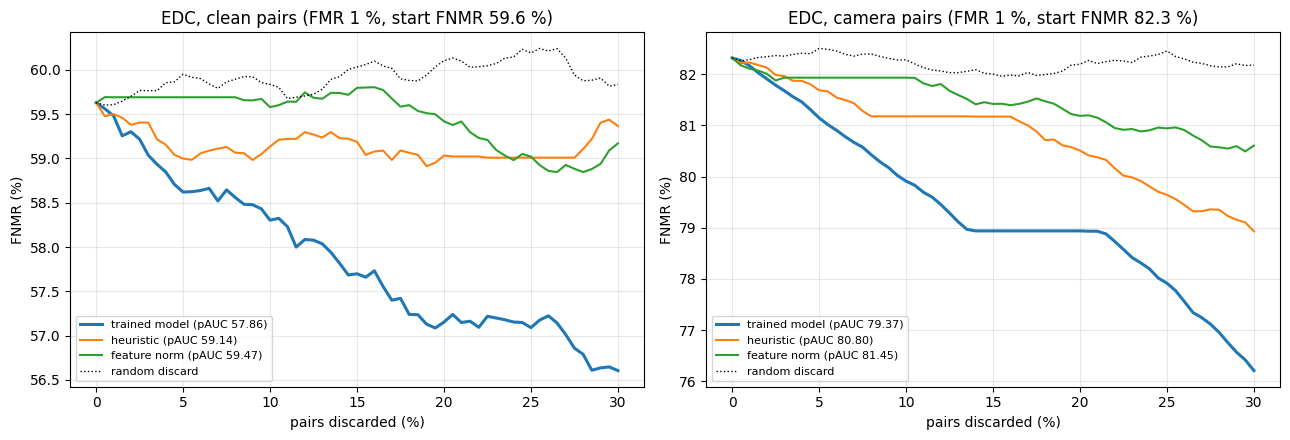

clean {'trained model': 57.86, 'heuristic': 59.14, 'feature norm': 59.47} (pAUC x100, lower = better)
camera {'trained model': 79.37, 'heuristic': 80.8, 'feature norm': 81.45} (pAUC x100, lower = better)


In [8]:
def edc(sim, q_pair, thr, steps=61):
    order = np.argsort(q_pair)                        # lowest quality first
    out = []
    for f in np.linspace(0, DISCARD_MAX, steps):
        keep = order[int(round(f * len(order))):]
        g = keep[same[keep]]
        out.append((f, float(np.mean(sim[g] < thr)) if len(g) else np.nan))
    return np.array(out)

results, fig, axes = {}, None, None
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ("clean", "camera")):
    sim = scores[name]["sim"]
    thr = float(np.quantile(sim[~same], 1 - FMR))     # FMR = 1 % on all pairs
    results[name] = {"threshold_fmr1": thr, "fnmr_at_0": float(np.mean(sim[same] < thr))}
    for m in METHODS:
        q = scores[name]["q"][m]; qp = np.minimum(q[A], q[B])
        c = edc(sim, qp, thr)
        pauc = float(np.trapezoid(c[:, 1], c[:, 0]) / DISCARD_MAX)
        results[name][m] = {"pAUC_0_30": pauc, "fnmr_at_10": float(c[np.argmin(abs(c[:, 0] - .1)), 1]),
                            "fnmr_at_20": float(c[np.argmin(abs(c[:, 0] - .2)), 1])}
        ax.plot(c[:, 0] * 100, c[:, 1] * 100, lw=2.2 if m == "trained model" else 1.5, label=f"{m} (pAUC {pauc * 100:.2f})")
    rnd = np.random.default_rng(1).random(len(pairs))
    c = edc(sim, rnd, thr); ax.plot(c[:, 0] * 100, c[:, 1] * 100, "k:", lw=1, label="random discard")
    ax.set_title(f"EDC, {name} pairs (FMR 1 %, start FNMR {results[name]['fnmr_at_0'] * 100:.1f} %)")
    ax.set_xlabel("pairs discarded (%)"); ax.set_ylabel("FNMR (%)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "edc.png", dpi=130); plt.show()
for name in results:
    print(name, {m: round(results[name][m]["pAUC_0_30"] * 100, 2) for m in METHODS}, "(pAUC x100, lower = better)")

## 4. Agreement with the recogniser-based labels (held-out identities of notebook 01)

In [9]:
LAB = RAW / "labels"
rows = list(csv.DictReader((LAB / "labels.csv").open(encoding="utf-8")))
val = np.array([r["split"] == "val" for r in rows]); y = np.array([float(r["label"]) for r in rows])[val]
imgs = np.load(LAB / "images.npy", mmap_mode="r")[np.where(val)[0]]
def spearman(a, b): return float(np.corrcoef(np.argsort(np.argsort(a)), np.argsort(np.argsort(b)))[0, 1])
_, norm_val = features(np.asarray(imgs))
spear = {"trained model": spearman(quality.score_batch(list(imgs)), y),
         "heuristic": spearman(np.array([heuristic_score(im) for im in imgs]), y),
         "feature norm": spearman(norm_val, y)}
results["label_spearman_val"] = spear
for k, v in spear.items(): print(f"  {k:14s} Spearman with labels {v:+.3f}  ({val.sum()} crops, unseen identities)")

  trained model  Spearman with labels +0.728  (4800 crops, unseen identities)
  heuristic      Spearman with labels +0.247  (4800 crops, unseen identities)
  feature norm   Spearman with labels +0.200  (4800 crops, unseen identities)


## 5. Score falls with damage (camera-like set)

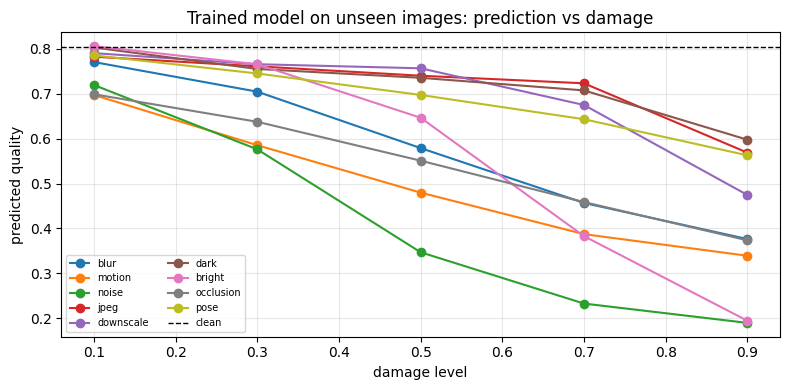

In [10]:
q = scores["camera"]["q"]["trained model"]
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 6); centre = (bins[:-1] + bins[1:]) / 2
for k in DAMAGES:
    m = kinds == k
    ax.plot(centre, [q[m & (levels > a) & (levels <= b)].mean() for a, b in zip(bins[:-1], bins[1:])], marker="o", label=k)
ax.axhline(q[kinds == "clean"].mean(), color="k", ls="--", lw=1, label="clean")
ax.set_xlabel("damage level"); ax.set_ylabel("predicted quality"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
ax.set_title("Trained model on unseen images: prediction vs damage"); plt.tight_layout(); plt.savefig(FIG / "damage_response.png", dpi=130); plt.show()

## 6. Accept threshold for the enrolment scan

Rule: the **lowest** quality score at which accepted images verify as well as clean photos — the FNMR of camera-like
genuine pairs whose two images both score ≥ t must be within 10 % of the FNMR of the clean pairs. Lower thresholds
let through images that hurt recognition; higher ones only make the scan slower.

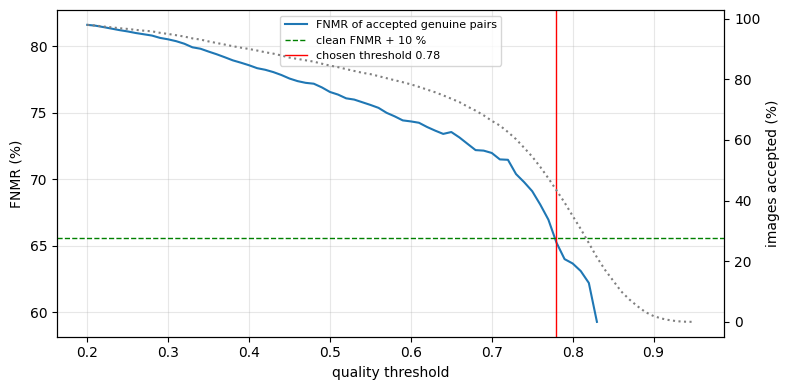

threshold 0.78: accepts 68.7 % of clean images; on the camera-like set:
  clean       69.0 % accepted
  blur         9.0 % accepted
  motion       4.5 % accepted
  noise        5.2 % accepted
  jpeg        30.6 % accepted
  downscale   29.3 % accepted
  dark        29.5 % accepted
  bright      26.5 % accepted
  occlusion    4.4 % accepted
  pose        19.3 % accepted


In [11]:
sim, thr = scores["camera"]["sim"], results["camera"]["threshold_fmr1"]
target = results["clean"]["fnmr_at_0"] * 1.10
qp = np.minimum(q[A], q[B])
grid = np.round(np.arange(0.20, 0.96, 0.01), 2)
curve = []
for t in grid:
    g = same & (qp >= t)
    curve.append((t, float(np.mean(sim[g] < thr)) if g.sum() >= 200 else np.nan, float(np.mean(q >= t))))
curve = np.array(curve)
ok = [t for t, f, _ in curve if not np.isnan(f) and f <= target]
THRESHOLD = float(ok[0]) if ok else float(np.nanmedian(q))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve[:, 0], curve[:, 1] * 100, label="FNMR of accepted genuine pairs")
ax.axhline(target * 100, color="g", ls="--", lw=1, label="clean FNMR + 10 %")
ax.axvline(THRESHOLD, color="r", lw=1, label=f"chosen threshold {THRESHOLD:.2f}")
ax2 = ax.twinx(); ax2.plot(curve[:, 0], curve[:, 2] * 100, color="grey", ls=":", label="images accepted (%)"); ax2.set_ylabel("images accepted (%)")
ax.set_xlabel("quality threshold"); ax.set_ylabel("FNMR (%)"); ax.legend(loc="upper center", fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "threshold.png", dpi=130); plt.show()
accepted_clean = float(np.mean(scores["clean"]["q"]["trained model"] >= THRESHOLD))
accepted_damaged = {k: float(np.mean(q[kinds == k] >= THRESHOLD)) for k in ["clean", *DAMAGES]}
print(f"threshold {THRESHOLD:.2f}: accepts {accepted_clean * 100:.1f} % of clean images; on the camera-like set:")
for k, v in accepted_damaged.items(): print(f"  {k:10s} {v * 100:5.1f} % accepted")
results["threshold"] = dict(value=THRESHOLD, rule="lowest t with FNMR(camera pairs, both >= t) <= 1.1 x clean FNMR",
                            target_fnmr=target, accepted_clean=accepted_clean, accepted_by_damage=accepted_damaged)

## 7. Save the threshold into `face_quality.pt` and the results to `results.json`

In [12]:
path = REPO / "ml" / "face_quality" / "face_quality.pt"
payload = torch.load(path, map_location="cpu", weights_only=True)
payload["threshold"] = THRESHOLD
payload["threshold_status"] = "chosen in 03_evaluate.ipynb: " + results["threshold"]["rule"]
payload["evaluation"] = {k: v for k, v in results.items()}
torch.save(payload, path)
(REPO / "ml" / "face_quality" / "results.json").write_text(json.dumps(results, indent=1), encoding="utf-8")
quality._state.clear(); print("threshold in the weights:", quality.threshold())

threshold in the weights: 0.78
